In [1]:
!python -m pip3 install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu126


c:\Users\ANING\anaconda3\envs\unity\python.exe: No module named pip3


In [1]:
import os
import numpy as np
from models import drunet
from models import fdncnn
from models import basicblocks
from models import basicblock
from models import network_dncnn
from models import network_unet

## Quick Test

In [2]:
import torch
import scipy.io
import matplotlib.pyplot as plt
import torchkbnufft as tkbn
import optalg_Tao_Pytorch as opt
from models.drunet import DRUNet

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

im_type = 'Brain'  # 'Brain' or 'Knee'

if im_type == 'Brain':
    model_path = 'norm-equivMSECh1_20240320_SE_DRUCNNBrainDenoise_sigma0.1.pth'
else:
    model_path = 'norm-equivMSECh1_20240320_SE_DRUCNNKneeDenoise_sigma0.1.pth'

model = DRUNet(blind=True, mode='norm-equiv', in_nc=1, out_nc=1).to(device)
model.load_state_dict(torch.load(model_path, map_location=device))
model.eval()
print(f'Model loaded: {model_path}')

Using device: cuda:0
Model loaded: norm-equivMSECh1_20240320_SE_DRUCNNBrainDenoise_sigma0.1.pth


In [17]:
im_index = '2'
if im_type == 'Brain':
    data = scipy.io.loadmat(f'image/BrainDeepGT_{im_index}.mat')
else:
    data = scipy.io.loadmat(f'image/KneeGT_{im_index}.mat')

im = data['im_real'] + 1j * data['im_imag']
im = im / np.max(np.abs(im))
im_original = im.copy()
print(f'Image shape: {im.shape}')

plt.figure(figsize=(5, 5))
plt.imshow(np.abs(im_original), cmap='gray')
plt.title('Ground Truth')
plt.axis('off')
plt.colorbar()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'image/BrainDeepGT_2.mat'

In [4]:
noise_level = 1e-3 if im_type == 'Brain' else 3e-4

# Keep full trajectory for acceleration experiments
trj_full = np.load('data/spiral/trj.npy')
mps      = np.load('data/spiral/mpsSim32.npy')
trj      = trj_full[0:-1:6, :, :]  # paper setting: 6 interleaves

im_size  = im.shape
im_torch = torch.tensor(im).unsqueeze(0).unsqueeze(0).to(torch.complex64).to(device)

trj_reshape = trj.reshape(1, trj.shape[0] * trj.shape[1], trj.shape[2])
ktraj       = torch.tensor(trj_reshape, dtype=torch.float).permute(0, 2, 1).to(device)

nufft_ob    = tkbn.KbNufft(im_size=im_size, device=device)
adjnufft_ob = tkbn.KbNufftAdjoint(im_size=im_size, device=device)
smaps       = torch.tensor(mps).unsqueeze(0).to(device)

Ax_raw  = lambda x: nufft_ob(x, ktraj, smaps=smaps.to(x))
ATx_raw = lambda x: adjnufft_ob(x, ktraj, smaps=smaps.to(x))

L    = opt.Power_Iter(Ax_raw, ATx_raw, im_size, tol=1e-6, device=device)
L_sr = torch.sqrt(L)
Ax   = lambda x: Ax_raw(x) / L_sr
ATx  = lambda x: ATx_raw(x) / L_sr

b = Ax(im_torch)
b_m, b_n, b_k = b.shape
torch.manual_seed(2); noise_real = torch.randn(b_m, b_n, b_k, device=device)
torch.manual_seed(5); noise_imag = torch.randn(b_m, b_n, b_k, device=device)
b_noise = b + noise_level * (noise_real + 1j * noise_imag)

snr = 10 * torch.log10(torch.norm(b) / torch.norm(b_noise - b))
print(f'SNR: {snr.item():.2f} dB | trj_full: {trj_full.shape} | subsampled: {trj.shape}')

SNR: 14.54 dB | trj_full: (32, 1688, 2) | subsampled: (6, 1688, 2)


In [5]:
MaxIter = 200

x_recon, psnr_list, time_list, fixed_list = opt.ISTA_PnP(
    MaxIter, Ax, ATx, b_noise,
    denoiser=model, isPred=False,
    original=im_original, verbose=True, device=device,
)
print(f'\nFinal PSNR: {psnr_list[-1]:.2f} dB')

ISTA PnP: 100%|██████████| 200/200 [01:53<00:00,  1.76it/s, psnr=33.90855%]


Final PSNR: 33.91 dB


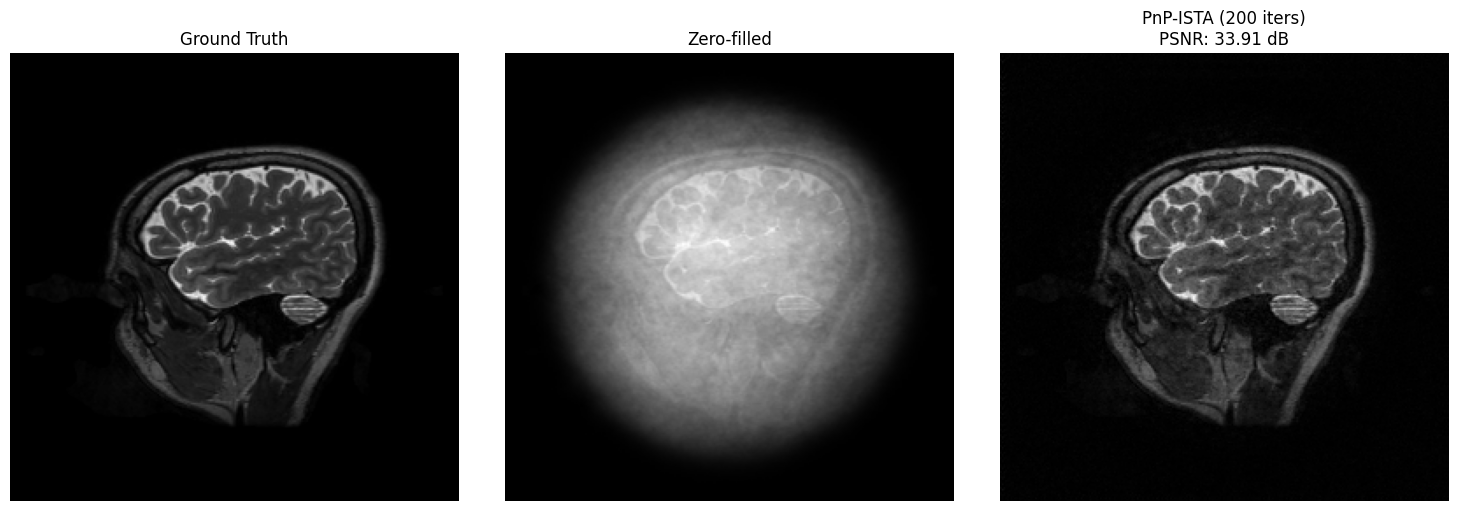

In [6]:
x_np   = torch.squeeze(torch.abs(x_recon)).cpu().detach().numpy()
adj_np = torch.squeeze(torch.abs(ATx(b_noise))).cpu().detach().numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, img, title in zip(
    axes,
    [np.abs(im_original), adj_np, x_np],
    ['Ground Truth', 'Zero-filled', f'PnP-ISTA ({MaxIter} iters)\nPSNR: {psnr_list[-1]:.2f} dB']
):
    ax.imshow(img, cmap='gray'); ax.set_title(title); ax.axis('off')
plt.tight_layout(); plt.show()

In [9]:
!pip install scikit-image

  Using cached scikit_image-0.26.0-cp313-cp313-win_amd64.whl.metadata (15 kB)
Using cached scikit_image-0.26.0-cp313-cp313-win_amd64.whl (11.9 MB)

   ---------------------------------------- 0/4 [tifffile]
   -------------------- ------------------- 2/4 [imageio]
   -------------------- ------------------- 2/4 [imageio]
   -------------------- ------------------- 2/4 [imageio]
   ------------------------------ --------- 3/4 [scikit-image]
   ------------------------------ --------- 3/4 [scikit-image]
   ------------------------------ --------- 3/4 [scikit-image]
   ------------------------------ --------- 3/4 [scikit-image]
   ------------------------------ --------- 3/4 [scikit-image]
   ------------------------------ --------- 3/4 [scikit-image]
   ------------------------------ --------- 3/4 [scikit-image]
   ---------------------------------------- 4/4 [scikit-image]



---
## Full Experimental Setup
Compares **PnP-ISTA** (no preconditioner), **Pre1-PnP** (fixed Chebyshev), and **Dynamic PnP** (quasi-Newton)
across spiral and radial trajectories at varying acceleration factors.

Metrics: PSNR vs iteration, PSNR vs runtime, SSIM, fixed-point residual (stability).

In [7]:
# pip install scikit-image  (if not already installed)
from skimage.metrics import structural_similarity as ssim_metric

In [8]:
def build_spiral_ops(step):
    """Normalized spiral forward/adjoint for a given step (arm subsampling)."""
    trj_sub     = trj_full[0:-1:step, :, :]
    n_arms      = len(trj_sub)
    trj_reshape = trj_sub.reshape(1, trj_sub.shape[0] * trj_sub.shape[1], trj_sub.shape[2])
    kt          = torch.tensor(trj_reshape, dtype=torch.float).permute(0, 2, 1).to(device)
    Ax_r   = lambda x, k=kt: nufft_ob(x, k, smaps=smaps.to(x))
    ATx_r  = lambda x, k=kt: adjnufft_ob(x, k, smaps=smaps.to(x))
    L_s    = opt.Power_Iter(Ax_r, ATx_r, im_size, tol=1e-6, device=device)
    L_sr_s = torch.sqrt(L_s)
    Ax_n   = lambda x, k=kt, l=L_sr_s: nufft_ob(x, k, smaps=smaps.to(x)) / l
    ATx_n  = lambda x, k=kt, l=L_sr_s: adjnufft_ob(x, k, smaps=smaps.to(x)) / l
    return Ax_n, ATx_n, n_arms


def build_radial_ops(nspokes, spokelength=1024):
    """Normalized golden-angle radial forward/adjoint for a given number of spokes."""
    ga = np.deg2rad(180 / ((1 + np.sqrt(5)) / 2))
    kx = np.zeros((nspokes, spokelength, 1))
    ky = np.zeros((nspokes, spokelength, 1))
    ky[0, :, 0] = np.linspace(-np.pi, np.pi, spokelength)
    for i in range(1, nspokes):
        kx[i,:,0] = np.cos(ga)*kx[i-1,:,0] - np.sin(ga)*ky[i-1,:,0]
        ky[i,:,0] = np.sin(ga)*kx[i-1,:,0] + np.cos(ga)*ky[i-1,:,0]
    trj_r       = np.concatenate((kx, ky), axis=2)
    trj_reshape = trj_r.reshape(1, nspokes * spokelength, 2)
    kt          = torch.tensor(trj_reshape, dtype=torch.float).permute(0, 2, 1).to(device)
    Ax_r   = lambda x, k=kt: nufft_ob(x, k, smaps=smaps.to(x))
    ATx_r  = lambda x, k=kt: adjnufft_ob(x, k, smaps=smaps.to(x))
    L_s    = opt.Power_Iter(Ax_r, ATx_r, im_size, tol=1e-6, device=device)
    L_sr_s = torch.sqrt(L_s)
    Ax_n   = lambda x, k=kt, l=L_sr_s: nufft_ob(x, k, smaps=smaps.to(x)) / l
    ATx_n  = lambda x, k=kt, l=L_sr_s: adjnufft_ob(x, k, smaps=smaps.to(x)) / l
    return Ax_n, ATx_n


def simulate_measurements(Ax_fn, nl):
    """Apply forward model to im_torch and add complex Gaussian noise at level nl."""
    b     = Ax_fn(im_torch)
    bm, bn, bk = b.shape
    torch.manual_seed(2); nr = torch.randn(bm, bn, bk, device=device)
    torch.manual_seed(5); ni = torch.randn(bm, bn, bk, device=device)
    return b + nl * (nr + 1j * ni)


def run_all_methods(Ax_fn, ATx_fn, b_n, n_iters):
    """Run PnP-ISTA, Pre1-PnP and Dynamic-PnP; return dict of results."""
    res = {}

    # --- PnP-ISTA (no preconditioner) ---
    x, psnr, t, fixed = opt.ISTA_PnP(
        n_iters, Ax_fn, ATx_fn, b_n, denoiser=model,
        isPred=False, original=im_original, verbose=False, device=device)
    xnp = torch.squeeze(torch.abs(x)).cpu().detach().numpy()
    res['PnP-ISTA'] = {'x': xnp, 'psnr': psnr, 'time': t, 'fixed': fixed,
                       'ssim': ssim_metric(np.abs(im_original), xnp, data_range=1.0)}

    # --- Pre1-PnP (fixed degree-1 Chebyshev preconditioner) ---
    w1 = lambda xx: 2*xx - ATx_fn(Ax_fn(xx))
    x, psnr, t, fixed = opt.ISTA_PnP(
        n_iters, Ax_fn, ATx_fn, b_n, denoiser=model,
        isPred=True, w_pred=w1, original=im_original, verbose=False, device=device)
    xnp = torch.squeeze(torch.abs(x)).cpu().detach().numpy()
    res['Pre1-PnP'] = {'x': xnp, 'psnr': psnr, 'time': t, 'fixed': fixed,
                       'ssim': ssim_metric(np.abs(im_original), xnp, data_range=1.0)}

    # --- Dynamic PnP (quasi-Newton preconditioner) ---
    x, psnr, t, fixed, _ = opt.DynamicPnP(
        n_iters, Ax_fn, ATx_fn, b_n, denoiser=model,
        original=im_original, verbose=False, device=device)
    xnp = torch.squeeze(torch.abs(x)).cpu().detach().numpy()
    res['Dynamic-PnP'] = {'x': xnp, 'psnr': psnr, 'time': t, 'fixed': fixed,
                          'ssim': ssim_metric(np.abs(im_original), xnp, data_range=1.0)}

    return res


print('Helper functions defined.')

Helper functions defined.


In [10]:
# --- Spiral experiment ---
# Vary step size: more arms = lower R, fewer arms = higher R
# Paper formula: AF = π × Matrix Size / n_arms  (Nyquist-based)
# e.g. step=6 → 6 arms → AF = π×256/6 ≈ 134 ≈ 130x  (paper setting)
spiral_steps  = [2, 4, 6, 8, 16]   # step sizes
MaxIter_exp   = 200                  # set to 200 for paper results
spiral_results = {}

print('=== Spiral Experiment ===')
for step in spiral_steps:
    n_arms = len(trj_full[0:-1:step])
    R      = np.pi * im_size[0] / n_arms  # paper formula: AF = π × Matrix Size / n_arms
    print(f'\nStep={step} | Arms={n_arms} | R≈{R:.1f}x  ', end='', flush=True)

    Ax_s, ATx_s, n_arms = build_spiral_ops(step)
    b_s = simulate_measurements(Ax_s, noise_level)
    spiral_results[step] = run_all_methods(Ax_s, ATx_s, b_s, MaxIter_exp)
    spiral_results[step]['R'] = R

    for name, r in spiral_results[step].items():
        if isinstance(r, dict):
            print(f"  {name}: PSNR={r['psnr'][-1]:.2f} dB  SSIM={r['ssim']:.4f}")

print('\nDone.')

=== Spiral Experiment ===

Step=2 | Arms=16 | R≈50.3x    PnP-ISTA: PSNR=40.86 dB  SSIM=0.8227
  Pre1-PnP: PSNR=42.69 dB  SSIM=0.8313
  Dynamic-PnP: PSNR=43.72 dB  SSIM=0.8362

Step=4 | Arms=8 | R≈100.5x    PnP-ISTA: PSNR=35.97 dB  SSIM=0.7696
  Pre1-PnP: PSNR=38.09 dB  SSIM=0.7816
  Dynamic-PnP: PSNR=39.87 dB  SSIM=0.7913

Step=6 | Arms=6 | R≈134.0x    PnP-ISTA: PSNR=33.91 dB  SSIM=0.7262
  Pre1-PnP: PSNR=35.87 dB  SSIM=0.7351
  Dynamic-PnP: PSNR=38.26 dB  SSIM=0.7458

Step=8 | Arms=4 | R≈201.1x    PnP-ISTA: PSNR=30.98 dB  SSIM=0.6712
  Pre1-PnP: PSNR=32.20 dB  SSIM=0.6706
  Dynamic-PnP: PSNR=33.66 dB  SSIM=0.6670

Step=16 | Arms=2 | R≈402.1x    PnP-ISTA: PSNR=26.60 dB  SSIM=0.5527
  Pre1-PnP: PSNR=27.18 dB  SSIM=0.5295
  Dynamic-PnP: PSNR=27.26 dB  SSIM=0.4672

Done.


In [11]:
# --- Radial experiment ---
# Vary number of golden-angle spokes
# Paper formula: AF = N_spokes_fully_sampled / N_spokes_acquired
# N_spokes_fully_sampled ≈ Matrix Size (number of phase encoding lines in Cartesian)
radial_spokes  = [32, 21, 16, 8, 4]
radial_results = {}

print('=== Radial Experiment ===')
for nspokes in radial_spokes:
    R_approx = im_size[0] / nspokes  # paper formula: AF = Matrix Size / nspokes
    print(f'\nSpokes={nspokes} | R≈{R_approx:.1f}x  ', end='', flush=True)

    Ax_r, ATx_r = build_radial_ops(nspokes)
    b_r = simulate_measurements(Ax_r, noise_level)
    radial_results[nspokes] = run_all_methods(Ax_r, ATx_r, b_r, MaxIter_exp)
    radial_results[nspokes]['R'] = R_approx

    for name, r in radial_results[nspokes].items():
        if isinstance(r, dict):
            print(f"  {name}: PSNR={r['psnr'][-1]:.2f} dB  SSIM={r['ssim']:.4f}")

print('\nDone.')

=== Radial Experiment ===

Spokes=32 | R≈8.0x    PnP-ISTA: PSNR=31.89 dB  SSIM=0.6731
  Pre1-PnP: PSNR=32.21 dB  SSIM=0.6044
  Dynamic-PnP: PSNR=32.29 dB  SSIM=0.5218

Spokes=21 | R≈12.2x    PnP-ISTA: PSNR=30.29 dB  SSIM=0.6839
  Pre1-PnP: PSNR=30.71 dB  SSIM=0.6229
  Dynamic-PnP: PSNR=30.66 dB  SSIM=0.5055

Spokes=16 | R≈16.0x    PnP-ISTA: PSNR=29.03 dB  SSIM=0.6866
  Pre1-PnP: PSNR=29.42 dB  SSIM=0.6304
  Dynamic-PnP: PSNR=29.31 dB  SSIM=0.5453

Spokes=8 | R≈32.0x    PnP-ISTA: PSNR=26.92 dB  SSIM=0.6818
  Pre1-PnP: PSNR=27.20 dB  SSIM=0.6399
  Dynamic-PnP: PSNR=27.41 dB  SSIM=0.5676

Spokes=4 | R≈64.0x    PnP-ISTA: PSNR=25.31 dB  SSIM=0.6661
  Pre1-PnP: PSNR=25.53 dB  SSIM=0.6454
  Dynamic-PnP: PSNR=25.46 dB  SSIM=0.5269

Done.


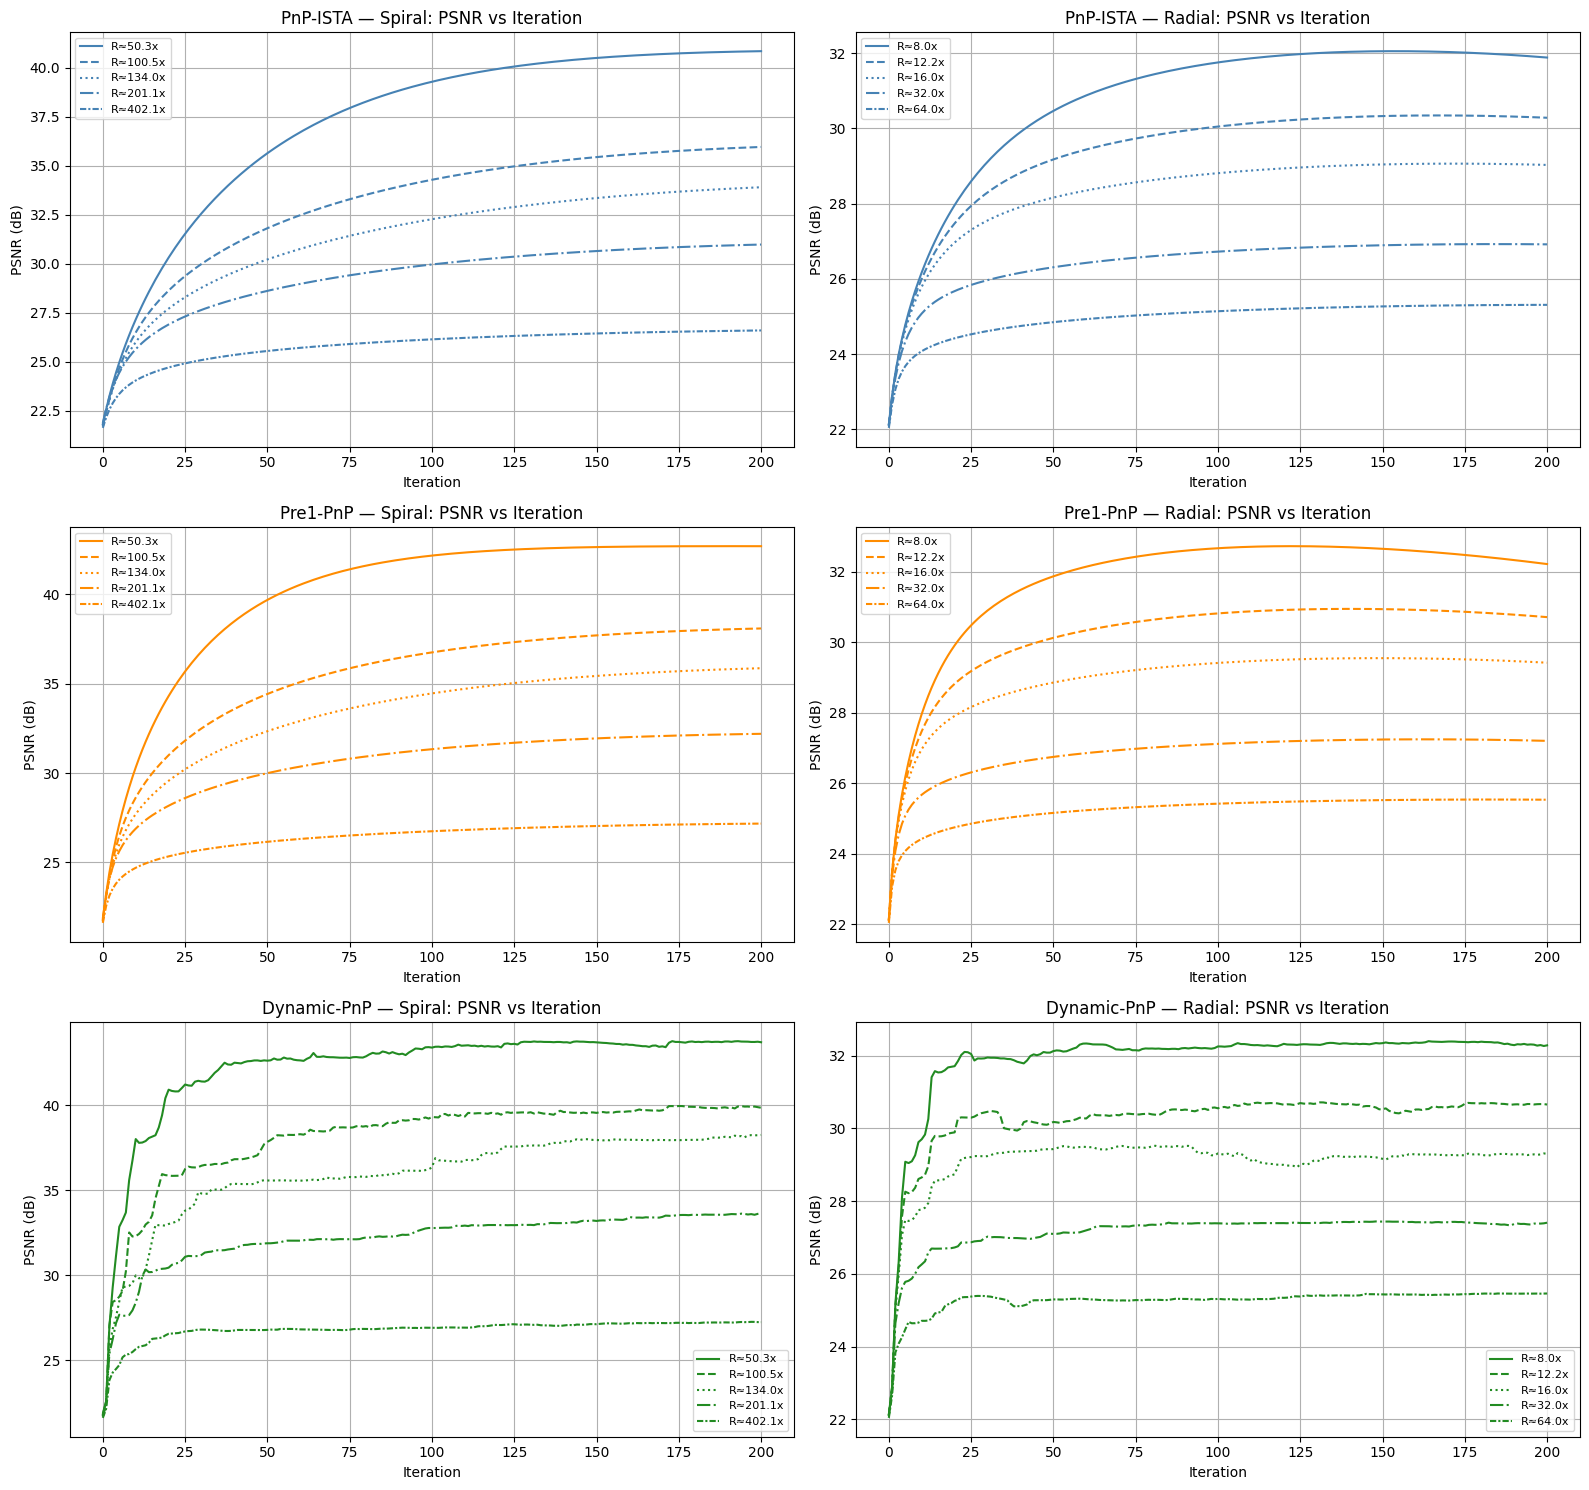

In [16]:
# --- PSNR vs Iteration --- one subplot per method ---
methods = ['PnP-ISTA', 'Pre1-PnP', 'Dynamic-PnP']
colors  = {'PnP-ISTA': 'steelblue', 'Pre1-PnP': 'darkorange', 'Dynamic-PnP': 'forestgreen'}
ls_map  = ['-', '--', ':', '-.', (0,(3,1,1,1))]

fig, axes = plt.subplots(len(methods), 2, figsize=(16, 5 * len(methods)))

for row, method in enumerate(methods):
    for col, (results, steps, label) in enumerate(
        [(spiral_results, spiral_steps, 'Spiral'), (radial_results, radial_spokes, 'Radial')]
    ):
        ax = axes[row, col]
        for i, key in enumerate(steps):
            R = results[key]['R']
            ax.plot(results[key][method]['psnr'],
                    color=colors[method], linestyle=ls_map[i],
                    label=f"R≈{R:.1f}x")
        ax.set_title(f'{method} — {label}: PSNR vs Iteration')
        ax.set_xlabel('Iteration')
        ax.set_ylabel('PSNR (dB)')
        ax.legend(fontsize=8)
        ax.grid(True)

plt.tight_layout()
plt.show()

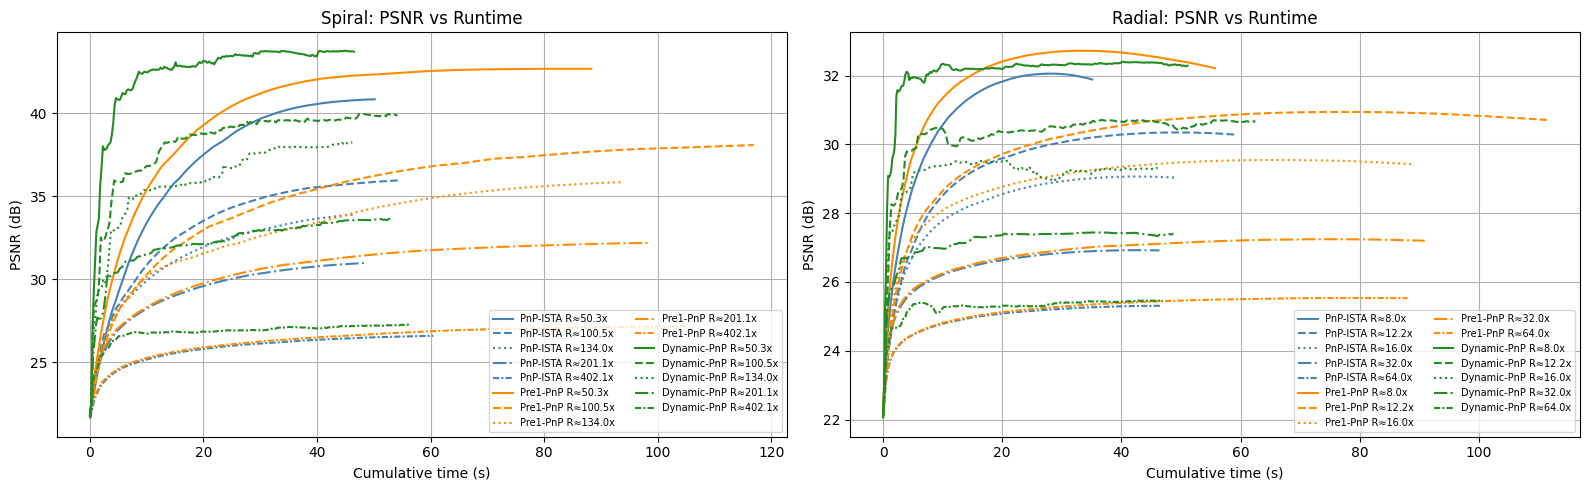

In [13]:
# --- PSNR vs Runtime ---
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, (results, steps, label) in zip(
    axes,
    [(spiral_results, spiral_steps, 'Spiral'), (radial_results, radial_spokes, 'Radial')]
):
    for method in methods:
        for i, key in enumerate(steps):
            R = results[key]['R']
            ax.plot(results[key][method]['time'],
                    results[key][method]['psnr'],
                    color=colors[method], linestyle=ls_map[i],
                    label=f"{method} R≈{R:.1f}x")
    ax.set_title(f'{label}: PSNR vs Runtime')
    ax.set_xlabel('Cumulative time (s)'); ax.set_ylabel('PSNR (dB)')
    ax.legend(fontsize=7, ncol=2); ax.grid(True)

plt.tight_layout(); plt.show()

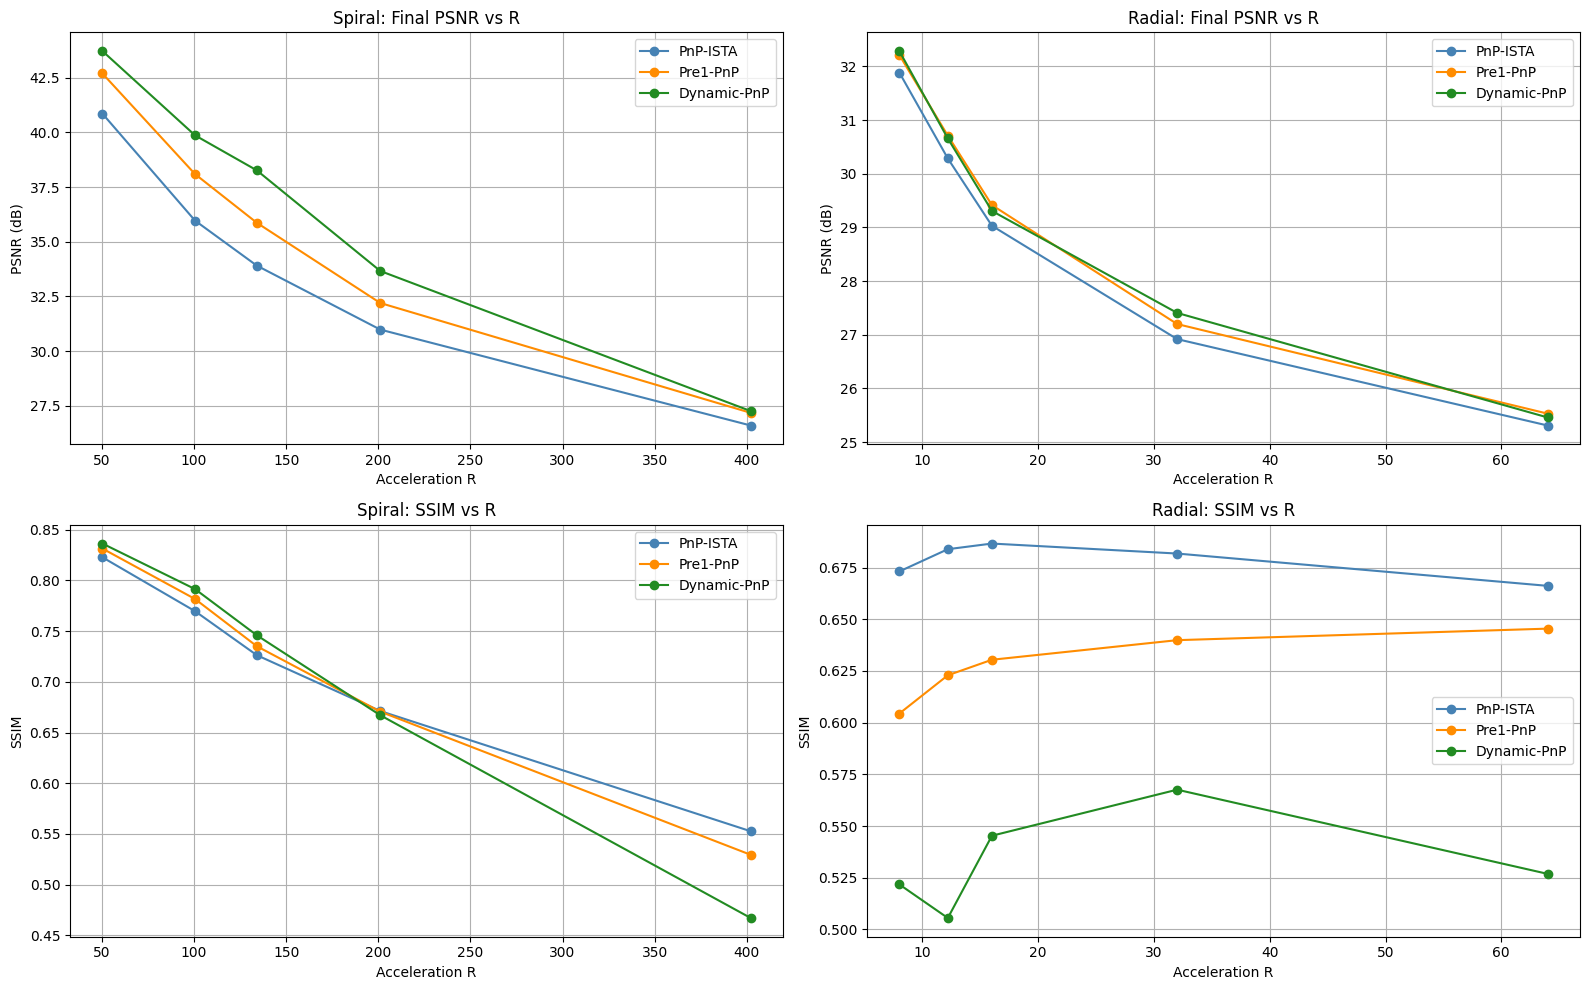

In [14]:
# --- Final PSNR and SSIM vs Acceleration ---
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for col, (results, steps, label) in enumerate(
    [(spiral_results, spiral_steps, 'Spiral'), (radial_results, radial_spokes, 'Radial')]
):
    R_vals = [results[k]['R'] for k in steps]

    # PSNR
    for method in methods:
        psnr_vals = [results[k][method]['psnr'][-1] for k in steps]
        axes[0, col].plot(R_vals, psnr_vals, marker='o', color=colors[method], label=method)
    axes[0, col].set_title(f'{label}: Final PSNR vs R')
    axes[0, col].set_xlabel('Acceleration R'); axes[0, col].set_ylabel('PSNR (dB)')
    axes[0, col].legend(); axes[0, col].grid(True)

    # SSIM
    for method in methods:
        ssim_vals = [results[k][method]['ssim'] for k in steps]
        axes[1, col].plot(R_vals, ssim_vals, marker='o', color=colors[method], label=method)
    axes[1, col].set_title(f'{label}: SSIM vs R')
    axes[1, col].set_xlabel('Acceleration R'); axes[1, col].set_ylabel('SSIM')
    axes[1, col].legend(); axes[1, col].grid(True)

plt.tight_layout(); plt.show()

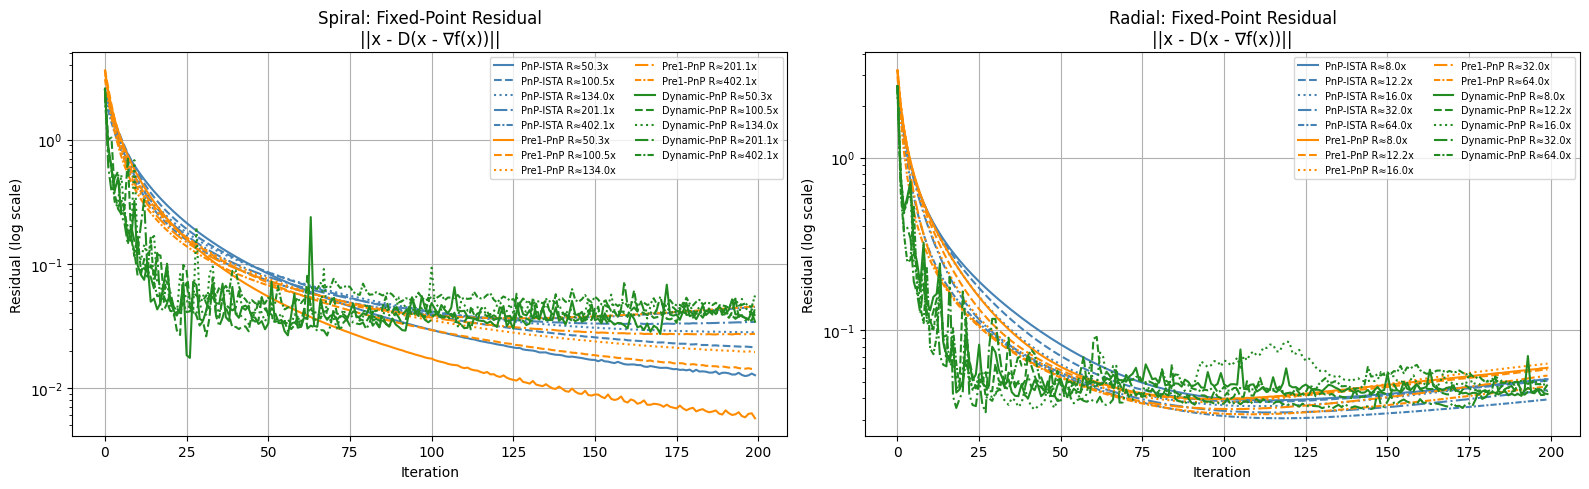

In [15]:
# --- Fixed-Point Residual (Stability) ---
# Lower residual = algorithm has converged = stable
# Residual that grows or oscillates = unstable at that acceleration
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, (results, steps, label) in zip(
    axes,
    [(spiral_results, spiral_steps, 'Spiral'), (radial_results, radial_spokes, 'Radial')]
):
    for method in methods:
        for i, key in enumerate(steps):
            R = results[key]['R']
            ax.semilogy(results[key][method]['fixed'],
                        color=colors[method], linestyle=ls_map[i],
                        label=f"{method} R≈{R:.1f}x")
    ax.set_title(f'{label}: Fixed-Point Residual\n||x - D(x - ∇f(x))||')
    ax.set_xlabel('Iteration'); ax.set_ylabel('Residual (log scale)')
    ax.legend(fontsize=7, ncol=2); ax.grid(True)

plt.tight_layout(); plt.show()